# Assignment 5: K-Means / Hierarchical Clustering on Sales Data
Dataset: [Sample Sales Data Dataset (Kaggle)](https://www.kaggle.com/datasets/kyanyoga/sample-sales-data)

Determine the number of clusters using the elbow method.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram

## Load the dataset

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


## Select numeric features and scale

In [4]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
df_clean = df.dropna(subset=features).copy()
X = StandardScaler().fit_transform(df_clean[features])

## Elbow method

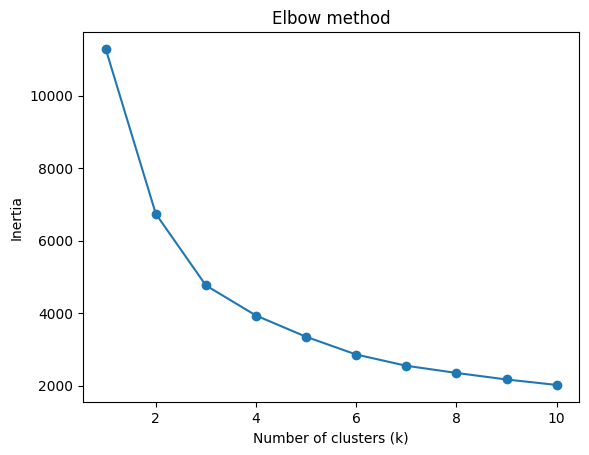

In [5]:
inertias = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)

plt.plot(range(1, 11), inertias, "o-")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow method")
plt.show()

In [6]:
diffs = np.diff(inertias)
second_diffs = np.diff(diffs)
best_k = int(np.argmax(second_diffs)) + 2
best_k = max(2, min(best_k, 10))
print(f"Selected number of clusters (elbow heuristic): k = {best_k}")

Selected number of clusters (elbow heuristic): k = 2


## Fit K-Means with the chosen k

In [7]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(X)
df_clean["kmeans_cluster"] = kmeans.labels_
df_clean["kmeans_cluster"].value_counts().sort_index()

kmeans_cluster
0    1597
1    1226
Name: count, dtype: int64

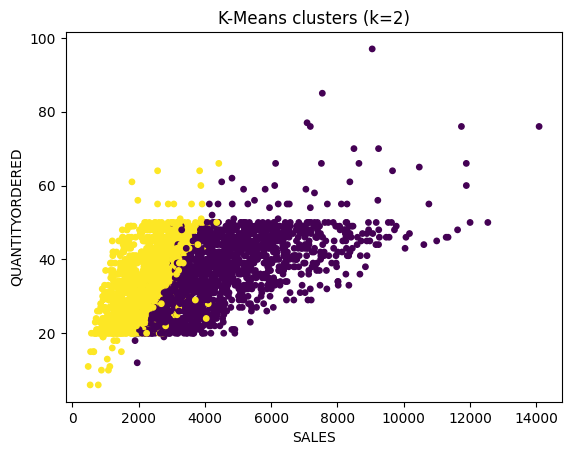

In [8]:
plt.scatter(df_clean["SALES"], df_clean["QUANTITYORDERED"], c=df_clean["kmeans_cluster"], cmap="viridis", s=15)
plt.xlabel("SALES")
plt.ylabel("QUANTITYORDERED")
plt.title(f"K-Means clusters (k={best_k})")
plt.show()

## Hierarchical clustering comparison

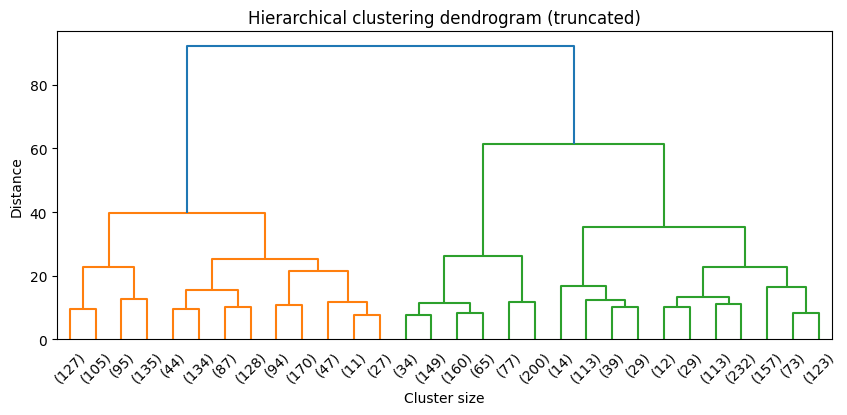

In [9]:
linked = linkage(X, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(linked, truncate_mode="lastp", p=30, show_leaf_counts=True)
plt.title("Hierarchical clustering dendrogram (truncated)")
plt.xlabel("Cluster size")
plt.ylabel("Distance")
plt.show()

In [10]:
hierarchical_labels = fcluster(linked, t=best_k, criterion="maxclust")
df_clean["hierarchical_cluster"] = hierarchical_labels
df_clean["hierarchical_cluster"].value_counts().sort_index()

hierarchical_cluster
1    1204
2    1619
Name: count, dtype: int64